# Goal

각 validatoin image 단위로 SimCC, pose 구현체간 AP를 비교한다. 이를 통해, pose 구현체의 AP가 낮은 케이스를 명확하게 파악한다.

## 체크할 것
- [x] Evaluation 대상 image id set이 동일한지 확인 -> 동일한 것 확인.
- [ ] SimCC 구현체 AP가 유의미하게 높은 image id 예측 결과 확인
- [ ] pose 구현체 AP가 유의미하게 높은 image id 예측 결과 확인

# Parameters

In [2]:
target_epoch = 139

# Library

In [3]:
import random
import orjson

from collections import OrderedDict
from contextlib import redirect_stdout

import cv2
import numpy as np
from PIL import Image
from IPython.display import display

%matplotlib inline
import torch
from matplotlib import pyplot as plt
from torchvision.io import read_image
from torchvision.transforms.v2 import ToPILImage
from torchvision.utils import draw_keypoints

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

to_pil = ToPILImage()

COLOR_MAGENTA = (255, 0, 255) # RGB
COLOR_CYAN = (0, 255, 255) # RGB
COLOR_YELLOW = (255, 255, 0) # RGB

connectivity = [[15, 13], [13, 11], [16, 14], [14, 12], [11, 12], [5, 11],
                [6, 12], [5, 6], [5, 7], [6, 8], [7, 9], [8, 10], [1, 2],
                [0, 1], [0, 2], [1, 3], [2, 4], [3, 5], [4, 6]]
kp_labels = ['nose', 'L-ey', 'R-ey', 'L-er', 'R-er',
             'L-sh', 'R-sh', 'L-elb', 'R-elb',
             'L-wr', 'R-wr', 'L-hip', 'R-hip',
             'L-kn', 'R-kn', 'L-ak', 'R-ak']

In [4]:
anno_fname = '/home/dev/data/coco//annotations/person_keypoints_val2017.json'
gt = orjson.loads(open(anno_fname).read())
print(f"gt.keys: {list(gt.keys())}")
print(f"gt['annotations'].keys: {list(gt['annotations'][0].keys())}")

gt_labels_per_image = dict()
for _ann in gt['annotations']:
    image_id = _ann['image_id']
    gt_labels_per_image.setdefault(image_id, [])
    gt_labels_per_image[image_id].append(_ann['keypoints'])

image_pool = list(gt_labels_per_image.keys())
print(f"gt images: {len(image_pool)}")

gt.keys: ['info', 'licenses', 'images', 'annotations', 'categories']
gt['annotations'].keys: ['segmentation', 'num_keypoints', 'area', 'iscrowd', 'keypoints', 'image_id', 'bbox', 'category_id', 'id']
gt images: 2693


In [5]:
simdr_preds = dict()

simdr_pred_fname = f"/home/dev/simcc/output/20250216a_res50_upfree_256x192/results/keypoints_val2017_results_0_ep{target_epoch}.json"
preds = orjson.loads(open(simdr_pred_fname).read())
for _pred in preds:
    image_id = _pred['image_id']
    simdr_preds.setdefault(image_id, [])
    simdr_preds[image_id].append(_pred['keypoints'])

print(f"len(simdr_preds): {len(simdr_preds)}")

len(simdr_preds): 2346


In [6]:
pose_preds = dict()

pose_pred_fname = f"/home/dev/pose/results/20250211a/pred_dumps/pred_dump_epoch{target_epoch}"
preds = orjson.loads(open(pose_pred_fname).read())
for _pred in preds:
    image_id = _pred['image_id']
    pose_preds.setdefault(image_id, [])
    pose_preds[image_id].append(_pred['keypoints'])

print(f"len(pose_preds): {len(pose_preds)}")

len(pose_preds): 2346


### ✅ SimCC, Pose 구현체의 validatoin 예측 값이 존재하는 image id set은 동일한 것을 확인함.

In [7]:
print(f"simdr - pose pred images: {set(simdr_preds.keys()) - set(pose_preds.keys())}")
print(f"pose - simdr pred images: {set(pose_preds.keys()) - set(simdr_preds.keys())}")

simdr - pose pred images: set()
pose - simdr pred images: set()


### 전체 image 기준 AP 체크

In [8]:
anno_fpath = "/home/dev/data/coco/annotations/person_keypoints_val2017.json"
coco_gt = COCO(anno_fpath)

loading annotations into memory...
Done (t=0.08s)
creating index...
index created!


In [9]:
def check_ap(pred_fname, image_ids):
    coco_dt = coco_gt.loadRes(pred_fname)
    coco_eval = COCOeval(coco_gt, coco_dt, 'keypoints')
    coco_eval.params.imgIds = image_ids
    coco_eval.evaluate()
    coco_eval.accumulate()
    coco_eval.summarize()

In [10]:
whole_image_ids = simdr_preds.keys()
print("*** SimCC ***")
check_ap(simdr_pred_fname, list(whole_image_ids))
print("\n\n*** Pose ***")
check_ap(pose_pred_fname, list(whole_image_ids))

*** SimCC ***
Loading and preparing results...
DONE (t=0.18s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *keypoints*
DONE (t=0.80s).
Accumulating evaluation results...
DONE (t=0.02s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets= 20 ] = 0.698
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets= 20 ] = 0.904
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets= 20 ] = 0.769
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets= 20 ] = 0.676
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets= 20 ] = 0.739
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 20 ] = 0.733
 Average Recall     (AR) @[ IoU=0.50      | area=   all | maxDets= 20 ] = 0.915
 Average Recall     (AR) @[ IoU=0.75      | area=   all | maxDets= 20 ] = 0.793
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=medium | maxDets= 20 ] = 0.702
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=

### image id 레벨 AP 체크

In [11]:
stat_names = ['Prec (IoU=0.50:0.95, area=   all)',
              'Prec (IoU=0.50     , area=   all)',
              'Prec (IoU=0.75     , area=   all)',
              'Prec (IoU=0.50:0.95, area=medium)',
              'Prec (IoU=0.50:0.95, area= large)',
              'Reca (IoU=0.50:0.95, area=   all)',
              'Reca (IoU=0.50     , area=   all)',
              'Reca (IoU=0.75     , area=   all)',
              'Reca (IoU=0.50:0.95, area=medium)',
              'Reca (IoU=0.50:0.95, area= large)']

In [12]:
def eval(pred_fname, image_ids):
    with redirect_stdout(None):
        coco_dt = coco_gt.loadRes(pred_fname)
        coco_eval = COCOeval(coco_gt, coco_dt, 'keypoints')
        coco_eval.params.imgIds = image_ids
        coco_eval.evaluate()
        coco_eval.accumulate()
        coco_eval.summarize()
    eval_stats = OrderedDict()
    for i, name in enumerate(stat_names):
        eval_stats[name] = float(coco_eval.stats[i])
    return eval_stats

In [13]:
def draw_gt_img(image_id, draw_sk=True):
    fname = str(image_id).zfill(12)
    image_path = f"/home/dev/pose/data/coco/images/val2017/{fname}.jpg"
    gt_samples = gt_labels_per_image[image_id]

    print("image id:", image_id)
    fname = str(image_id).zfill(12)
    image_path = f"/home/dev/pose/data/coco/images/val2017/{fname}.jpg"
    img = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    
    for i, _pred in enumerate(gt_samples):
        # draw keypoints
        pred = np.array(_pred).reshape(17,3)
        for kp_idx, (x, y, vis) in enumerate(pred):
            if vis > 0:
                img = cv2.circle(img, (int(x), int(y)), 4, COLOR_YELLOW, 3)
                kp_name = kp_labels[kp_idx]
                # img = cv2.putText(img, kp_name, (int(x)+5, int(y)+5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, COLOR_MAGENTA, 1)
                if draw_sk:
                    connected_keypoints = get_connected_keypoints(kp_idx)
                    for conn in connected_keypoints:
                        if pred[conn][2] != 0:
                            dst = (int(pred[conn][0]), int(pred[conn][1]))
                            img = cv2.line(img, (int(x), int(y)), dst, COLOR_YELLOW, 1)
    
    #plt.imshow(img)
    #plt.show()
    return img

In [14]:
def get_connected_keypoints(keypoint_idx):
    ret = set()
    for a, b in connectivity:
        if a == keypoint_idx:
            ret.add(b)
        elif b == keypoint_idx:
            ret.add(a)
    return list(ret)

In [15]:
def draw_pred_kp_with_caption(img, image_id, model, color, draw_sk=True):
    if model == 'simdr':
        preds_per_image = simdr_preds
    elif model == 'pose':
        preds_per_image = pose_preds
    else:
        raise Exception(f"Invalid model name: {model}")
    preds = preds_per_image[image_id]

    #fname = str(image_id).zfill(12)
    #image_path = f"/home/dev/pose/data/coco/images/val2017/{fname}.jpg"
    #img = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    
    for i, _pred in enumerate(preds):
        # draw keypoints
        pred = np.array(_pred).reshape(17,3)
        for kp_idx, (x, y, vis) in enumerate(pred):
            img = cv2.circle(img, (int(x), int(y)), 3, color, 3)
            kp_name = kp_labels[kp_idx]
            img = cv2.putText(img, kp_name, (int(x)+5, int(y)+5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)
            if draw_sk:
                connected_keypoints = get_connected_keypoints(kp_idx)
                for conn in connected_keypoints:
                    if pred[conn][2] != 0:
                        dst = (int(pred[conn][0]), int(pred[conn][1]))
                        img = cv2.line(img, (int(x), int(y)), dst, color, 1)

    #plt.imshow(img)
    #plt.show()
    return img

In [16]:
def check_ap_by_image_idx(idx, draw_simcc=True, draw_pose=True, skip_score=False):
    target_image_id = [list(simdr_preds.keys())[idx]]
    simcc_eval = eval(simdr_pred_fname, target_image_id)
    pose_eval = eval(pose_pred_fname, target_image_id)
    
    if skip_score is False:
        for name in stat_names:
            delta = simcc_eval[name]-pose_eval[name]
            mark = ""
            if delta > 0:
                mark = "✅"
            if delta < 0:
                mark = "🔥"
            print(f"{name} | SimCC({simcc_eval[name]:.4f}) | Pose({pose_eval[name]:.4f} | SimCC-Pose({delta:.4f}) {mark}")

    image_id = target_image_id[0]
    img = draw_gt_img(image_id)
    if draw_simcc:
        img = draw_pred_kp_with_caption(img=img, image_id=image_id, model='simdr', color=COLOR_MAGENTA)
    if draw_pose:
        img = draw_pred_kp_with_caption(img=img, image_id=image_id, model='pose', color=COLOR_CYAN)
    
    plt.imshow(img)
    plt.show()


*** GT & SimCC ***
Prec (IoU=0.50:0.95, area=   all) | SimCC(0.9505) | Pose(0.9505 | SimCC-Pose(0.0000) 
Prec (IoU=0.50     , area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Prec (IoU=0.75     , area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Prec (IoU=0.50:0.95, area=medium) | SimCC(0.9000) | Pose(0.9000 | SimCC-Pose(0.0000) 
Prec (IoU=0.50:0.95, area= large) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Reca (IoU=0.50:0.95, area=   all) | SimCC(0.9500) | Pose(0.9500 | SimCC-Pose(0.0000) 
Reca (IoU=0.50     , area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Reca (IoU=0.75     , area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Reca (IoU=0.50:0.95, area=medium) | SimCC(0.9000) | Pose(0.9000 | SimCC-Pose(0.0000) 
Reca (IoU=0.50:0.95, area= large) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
image id: 9891


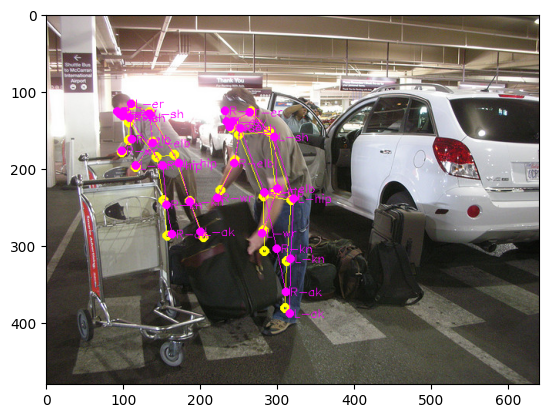


*** GT & Pose ***
image id: 9891


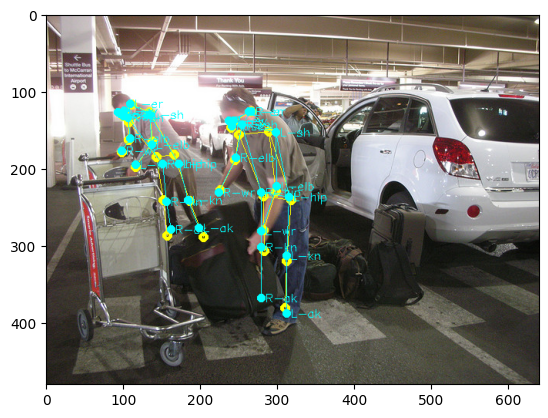

In [17]:
idx = 2012

print("\n*** GT & SimCC ***")
check_ap_by_image_idx(idx, draw_simcc=True, draw_pose=False)

print("\n*** GT & Pose ***")
check_ap_by_image_idx(idx, draw_simcc=False, draw_pose=True, skip_score=True)


*** GT & SimCC ***
Prec (IoU=0.50:0.95, area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Prec (IoU=0.50     , area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Prec (IoU=0.75     , area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Prec (IoU=0.50:0.95, area=medium) | SimCC(-1.0000) | Pose(-1.0000 | SimCC-Pose(0.0000) 
Prec (IoU=0.50:0.95, area= large) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Reca (IoU=0.50:0.95, area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Reca (IoU=0.50     , area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Reca (IoU=0.75     , area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Reca (IoU=0.50:0.95, area=medium) | SimCC(-1.0000) | Pose(-1.0000 | SimCC-Pose(0.0000) 
Reca (IoU=0.50:0.95, area= large) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
image id: 89078


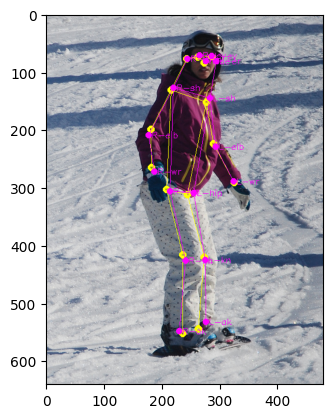


*** GT & Pose ***
image id: 89078


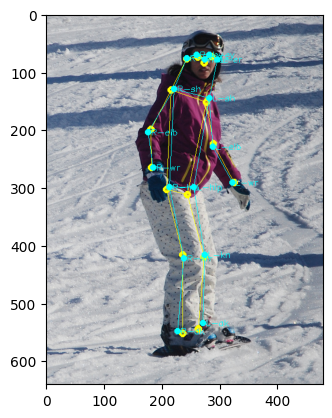

In [18]:
idx = 1800

print("\n*** GT & SimCC ***")
check_ap_by_image_idx(idx, draw_simcc=True, draw_pose=False)

print("\n*** GT & Pose ***")
check_ap_by_image_idx(idx, draw_simcc=False, draw_pose=True, skip_score=True)


*** GT & SimCC ***
Prec (IoU=0.50:0.95, area=   all) | SimCC(0.7604) | Pose(0.7109 | SimCC-Pose(0.0495) ✅
Prec (IoU=0.50     , area=   all) | SimCC(1.0000) | Pose(0.7525 | SimCC-Pose(0.2475) ✅
Prec (IoU=0.75     , area=   all) | SimCC(0.7525) | Pose(0.7525 | SimCC-Pose(0.0000) 
Prec (IoU=0.50:0.95, area=medium) | SimCC(0.2000) | Pose(0.0000 | SimCC-Pose(0.2000) ✅
Prec (IoU=0.50:0.95, area= large) | SimCC(0.9442) | Pose(0.9442 | SimCC-Pose(0.0000) 
Reca (IoU=0.50:0.95, area=   all) | SimCC(0.7750) | Pose(0.7250 | SimCC-Pose(0.0500) ✅
Reca (IoU=0.50     , area=   all) | SimCC(1.0000) | Pose(0.7500 | SimCC-Pose(0.2500) ✅
Reca (IoU=0.75     , area=   all) | SimCC(0.7500) | Pose(0.7500 | SimCC-Pose(0.0000) 
Reca (IoU=0.50:0.95, area=medium) | SimCC(0.2000) | Pose(0.0000 | SimCC-Pose(0.2000) ✅
Reca (IoU=0.50:0.95, area= large) | SimCC(0.9667) | Pose(0.9667 | SimCC-Pose(0.0000) 
image id: 47585


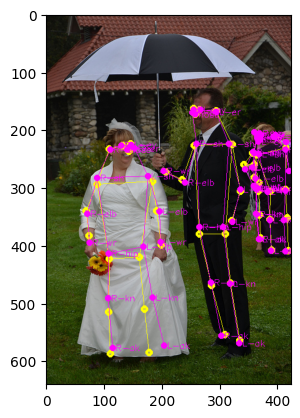


*** GT & Pose ***
image id: 47585


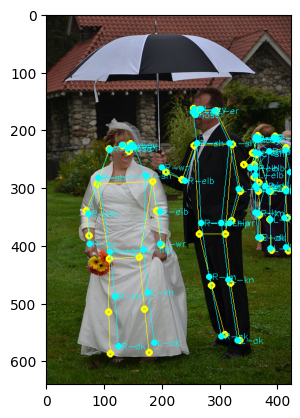

In [19]:
idx = 1020

print("\n*** GT & SimCC ***")
check_ap_by_image_idx(idx, draw_simcc=True, draw_pose=False)

print("\n*** GT & Pose ***")
check_ap_by_image_idx(idx, draw_simcc=False, draw_pose=True, skip_score=True)


*** GT & SimCC ***
Prec (IoU=0.50:0.95, area=   all) | SimCC(1.0000) | Pose(0.9000 | SimCC-Pose(0.1000) ✅
Prec (IoU=0.50     , area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Prec (IoU=0.75     , area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Prec (IoU=0.50:0.95, area=medium) | SimCC(1.0000) | Pose(0.9000 | SimCC-Pose(0.1000) ✅
Prec (IoU=0.50:0.95, area= large) | SimCC(-1.0000) | Pose(-1.0000 | SimCC-Pose(0.0000) 
Reca (IoU=0.50:0.95, area=   all) | SimCC(1.0000) | Pose(0.9000 | SimCC-Pose(0.1000) ✅
Reca (IoU=0.50     , area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Reca (IoU=0.75     , area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Reca (IoU=0.50:0.95, area=medium) | SimCC(1.0000) | Pose(0.9000 | SimCC-Pose(0.1000) ✅
Reca (IoU=0.50:0.95, area= large) | SimCC(-1.0000) | Pose(-1.0000 | SimCC-Pose(0.0000) 
image id: 125257


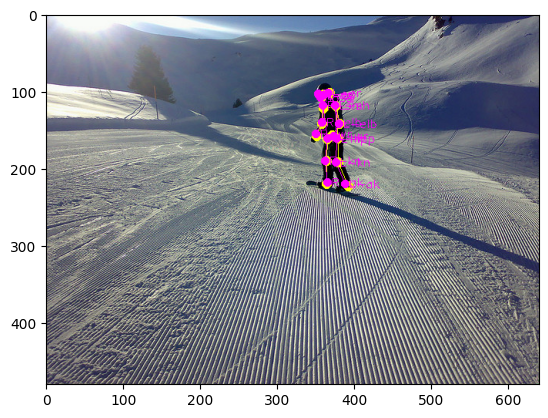


*** GT & Pose ***
image id: 125257


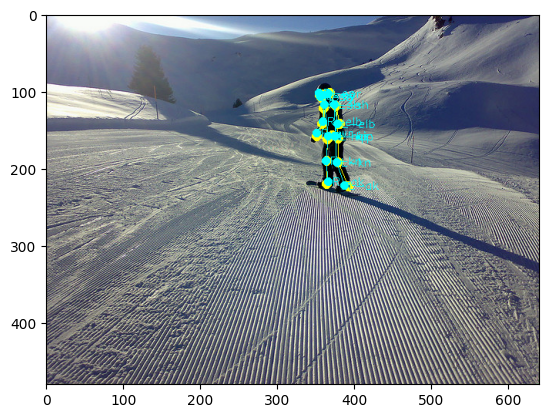

In [20]:
idx = 1573

print("\n*** GT & SimCC ***")
check_ap_by_image_idx(idx, draw_simcc=True, draw_pose=False)

print("\n*** GT & Pose ***")
check_ap_by_image_idx(idx, draw_simcc=False, draw_pose=True, skip_score=True)


*** GT & SimCC ***
Prec (IoU=0.50:0.95, area=   all) | SimCC(0.9000) | Pose(0.9000 | SimCC-Pose(0.0000) 
Prec (IoU=0.50     , area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Prec (IoU=0.75     , area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Prec (IoU=0.50:0.95, area=medium) | SimCC(0.9000) | Pose(0.9000 | SimCC-Pose(0.0000) 
Prec (IoU=0.50:0.95, area= large) | SimCC(-1.0000) | Pose(-1.0000 | SimCC-Pose(0.0000) 
Reca (IoU=0.50:0.95, area=   all) | SimCC(0.9000) | Pose(0.9000 | SimCC-Pose(0.0000) 
Reca (IoU=0.50     , area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Reca (IoU=0.75     , area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Reca (IoU=0.50:0.95, area=medium) | SimCC(0.9000) | Pose(0.9000 | SimCC-Pose(0.0000) 
Reca (IoU=0.50:0.95, area= large) | SimCC(-1.0000) | Pose(-1.0000 | SimCC-Pose(0.0000) 
image id: 464476


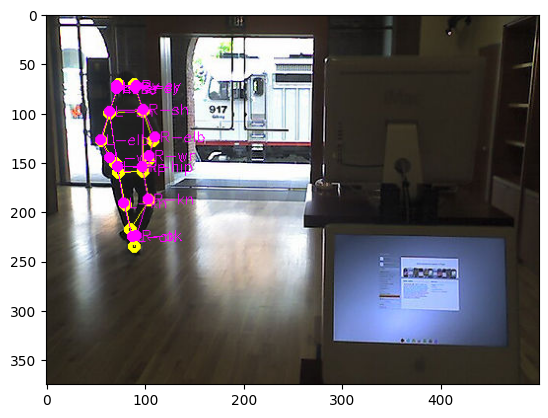


*** GT & Pose ***
image id: 464476


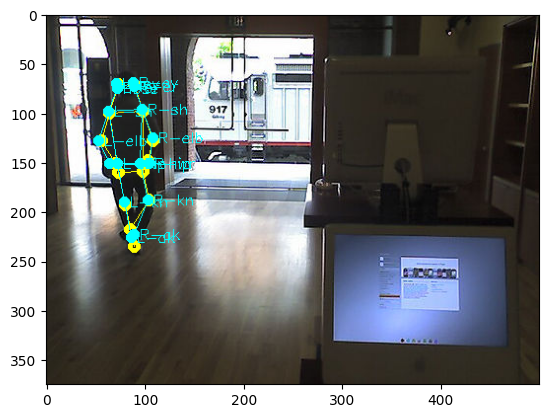

In [21]:
idx = 1114

print("\n*** GT & SimCC ***")
check_ap_by_image_idx(idx, draw_simcc=True, draw_pose=False)

print("\n*** GT & Pose ***")
check_ap_by_image_idx(idx, draw_simcc=False, draw_pose=True, skip_score=True)


*** GT & SimCC ***
Prec (IoU=0.50:0.95, area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Prec (IoU=0.50     , area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Prec (IoU=0.75     , area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Prec (IoU=0.50:0.95, area=medium) | SimCC(-1.0000) | Pose(-1.0000 | SimCC-Pose(0.0000) 
Prec (IoU=0.50:0.95, area= large) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Reca (IoU=0.50:0.95, area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Reca (IoU=0.50     , area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Reca (IoU=0.75     , area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Reca (IoU=0.50:0.95, area=medium) | SimCC(-1.0000) | Pose(-1.0000 | SimCC-Pose(0.0000) 
Reca (IoU=0.50:0.95, area= large) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
image id: 186042


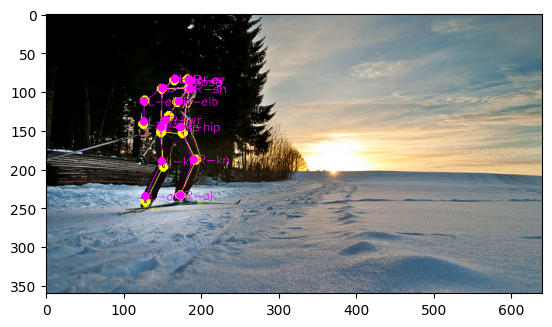


*** GT & Pose ***
image id: 186042


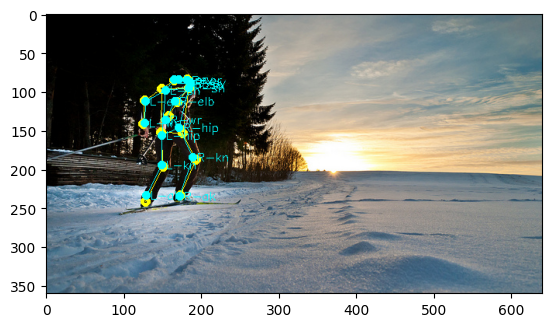

In [22]:
idx = 960

print("\n*** GT & SimCC ***")
check_ap_by_image_idx(idx, draw_simcc=True, draw_pose=False)

print("\n*** GT & Pose ***")
check_ap_by_image_idx(idx, draw_simcc=False, draw_pose=True, skip_score=True)

index: 1011
Prec (IoU=0.50:0.95, area=   all) | SimCC(0.9000) | Pose(0.8000 | SimCC-Pose(0.1000) ✅
Prec (IoU=0.50     , area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Prec (IoU=0.75     , area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Prec (IoU=0.50:0.95, area=medium) | SimCC(0.9000) | Pose(0.8000 | SimCC-Pose(0.1000) ✅
Prec (IoU=0.50:0.95, area= large) | SimCC(-1.0000) | Pose(-1.0000 | SimCC-Pose(0.0000) 
Reca (IoU=0.50:0.95, area=   all) | SimCC(0.9000) | Pose(0.8000 | SimCC-Pose(0.1000) ✅
Reca (IoU=0.50     , area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Reca (IoU=0.75     , area=   all) | SimCC(1.0000) | Pose(1.0000 | SimCC-Pose(0.0000) 
Reca (IoU=0.50:0.95, area=medium) | SimCC(0.9000) | Pose(0.8000 | SimCC-Pose(0.1000) ✅
Reca (IoU=0.50:0.95, area= large) | SimCC(-1.0000) | Pose(-1.0000 | SimCC-Pose(0.0000) 
image id: 49259


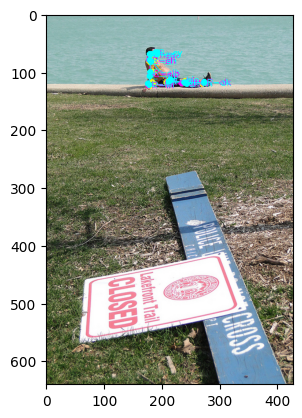

In [23]:
idx = random.randint(0, len(simdr_preds))
print(f"index: {idx}")

check_ap_by_image_idx(idx)